# Paired OD / cell count to dry weight

**SYNTHETIC / UNVERIFIED teaching example.** MIT licence (repository LICENSE). No measured species relationship or biological validation. Replace these pairs only with your own paired, legally reusable measurements. This notebook does not fetch or digitise data.

Install `pip install -e ".[tutorials,reports]" matplotlib`. Record wavelength, path, blank/dilution, counting method, strain and DW assay before using measured pairs.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from alga_twin.biomass_calibration import fit_biomass_calibration
from alga_twin.biomass_ui import synthetic_pairs

pairs = synthetic_pairs()
pairs

Out[1]: 
     signal  dry_weight
0  0.100000    0.060000
1  0.228571    0.114429
2  0.357143    0.160857
3  0.485714    0.215286
4  0.614286    0.264714
5  0.742857    0.319143
6  0.871429    0.365571
7  1.000000    0.420000


Fit X = c0 + c1 S (or c0 + c1 S + c2 S²) with an estimated intercept. Equal-weight ordinary least squares; coefficients have the output/input units documented in MODEL.md. Replicated pairs receive equal per-row weight. A high in-sample R² does not establish transferability or independent accuracy.

In [2]:
fits = {}
for degree in (1, 2):
    fits[degree] = fit_biomass_calibration(
        pairs,
        kind="OD",
        signal_unit="dimensionless",
        dry_weight_unit="g_DW/liter",
        degree=degree,
        species="SYNTHETIC",
        conditions="SYNTHETIC teaching pairs; no instrument; not a strain calibration",
        origin="SYNTHETIC",
    )
pd.DataFrame([{**f.report(), "degree": d} for d, f in fits.items()])

Out[2]: 
  kind  ...                                              scope
0   OD  ...  Paired proxy/DW calibration only; instrument a...
1   OD  ...  Paired proxy/DW calibration only; instrument a...

[2 rows x 15 columns]


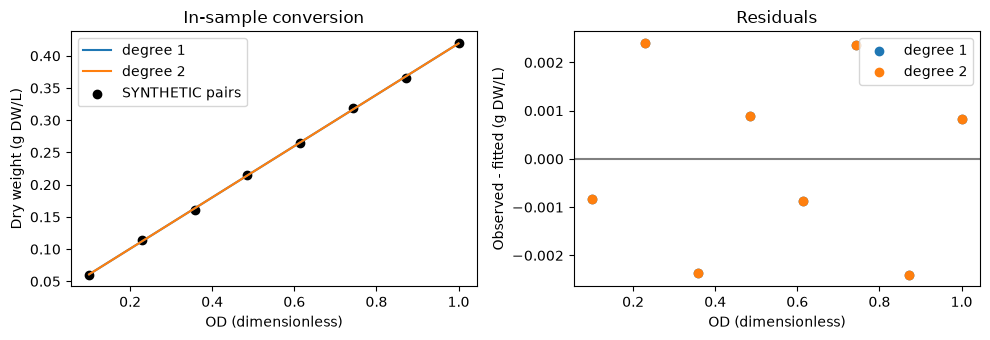

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for degree, fit in fits.items():
    x = np.linspace(*fit.domain, 100)
    ax[0].plot(x, fit.predict(x, unit="dimensionless"), label=f"degree {degree}")
    ax[1].scatter(fit.residuals.signal_canonical, fit.residuals.residual_g_DW_L, label=f"degree {degree}")
ax[0].scatter(pairs.signal, pairs.dry_weight, color="black", label="SYNTHETIC pairs")
ax[0].set(xlabel="OD (dimensionless)", ylabel="Dry weight (g DW/L)", title="In-sample conversion")
ax[1].axhline(0, color="gray")
ax[1].set(xlabel="OD (dimensionless)", ylabel="Observed - fitted (g DW/L)", title="Residuals")
for a in ax:
    a.legend()
fig.tight_layout()
plt.show()

In [4]:
fit = fits[1]
print("Within-domain conversion:", fit.predict([0.5], unit="dimensionless"), "g DW/L")
try:
    fit.predict([1.1], unit="dimensionless")
except ValueError as exc:
    print("Expected refusal:", exc)
else:
    raise AssertionError("Extrapolation must be refused")
assert fit.status == "UNVERIFIED" and fit.report()["interval"] is None

Within-domain conversion: [0.22009259] g DW/L
Expected refusal: Extrapolation refused: use proxy values within (0.1, 1.0) dimensionless; measure new paired dry weights to extend the calibration.


Cell counts use `kind="cell_count"` with explicit `cells/mL` or `cells/L`, converted to cells/L before fitting. DW accepts g_DW/liter or g_DW/meter**3. Carbon mass cannot be substituted; f_C remains unset. Conversion uncertainty is not propagated into growth-fit intervals. No confidence interval is estimated here.